# Au–Cu: phase diagrams from three DFT functionals

The Au–Cu phase diagram computed with landau from calphy free energies of ACE potentials fitted to LDA,
PBE and r$^2$SCAN data: the fcc solid solution, the liquid, and three ordered phases
(Au$_4$Cu$_2$, AuCu, AuCu$_3$).

- fcc and liquid: a CALPHAD-style Redlich–Kister surface $f(T, c)$ — `CalphadSurface2DInterpolator`
- ordered phases: a convex softplus surface around each stoichiometry — `SoftplusSurface2DInterpolator`
- boundaries sharpened with `ClausiusClapeyronRefiner`, triple points with `DelaunayTripleRefiner`

Writes `AuCu_Phasediagram_<functional>.svg` and `.png` (transparent) next to the notebook.

## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import landau as ld

warnings.simplefilter("ignore")

/home/pmrv/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-t1ibw7ia because there was an issue with the default path (/home/pmrv/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
FUNCTIONALS = {
    "LDA": "CuAu_ACE_LDA_V4.pkl.gz",
    "PBE": "CuAu_ACE_GGA_V4.pkl.gz",
    "rSCAN": "CuAu_ACE_RSCAN_V4.pkl.gz",
}

LABELS = {"fcc": "fcc", "lqd": "liquid", "au2cu": r"Au$_4$Cu$_2$", "aucu": "AuCu", "aucu3": r"AuCu$_3$"}
PHASE_COLOR = {"fcc": "#a1c9f4", "liquid": "#ffb482", r"Au$_4$Cu$_2$": "#8de5a1", "AuCu": "#ff9f9b",
               r"AuCu$_3$": "#d0bbff"}

T_MIN = 450.0
DT, MU = 4.0, np.linspace(-1.0, 0.85, 200)
MIN_C_WIDTH = 0.005

FIGSIZE = (7, 5.5)  # inches
FONTSIZE = 15
DPI = 150

## Data

One row per phase and Cu concentration, each with a free-energy sweep over temperature (eV/atom,
configurational entropy already included).

In [3]:
def load(path):
    raw = pd.read_pickle(path)
    return (raw.assign(n=raw.temperature.map(len)).sort_values("n", ascending=False)  # keep the longest sweep
               .drop_duplicates(["phase", "composition"]).drop(columns="n").sort_index())


raw = {key: load(path) for key, path in FUNCTIONALS.items()}
pd.concat({key: r.groupby("phase").composition.agg(["count", "min", "max"]) for key, r in raw.items()}, axis=1)

LDA                       PBE                     rSCAN            \
      count       min       max count       min       max count       min   
phase                                                                       
au2cu    21  0.199942  0.399884    21  0.199942  0.399884    21  0.199942   
aucu     11  0.449942  0.550058    11  0.449942  0.550058    11  0.449942   
aucu3    11  0.700000  0.800000    11  0.700000  0.800000    11  0.700000   
fcc      51  0.000000  1.000000    51  0.000000  1.000000    51  0.000000   
lqd      51  0.000000  1.000000    21  0.000000  1.000000    21  0.000000   

                 
            max  
phase            
au2cu  0.399884  
aucu   0.550058  
aucu3  0.800000  
fcc    1.000000  
lqd    1.000000

## Phases

In [4]:
def line(r):
    return ld.TemperatureDependentLinePhase(
        LABELS[r.phase], float(r.composition), np.asarray(r.temperature, float), np.asarray(r.free_energy, float),
        interpolator=ld.interpolate.SGTE(4),
    )


def solution(name, sub, num_coeffs, T_max):
    return ld.Surface2DInterpolatingPhase(
        LABELS[name], [line(r) for r in sub.itertuples()],
        surface_interpolator=ld.CalphadSurface2DInterpolator(
            num_coeffs=num_coeffs, terminal_sgte_order=4, coeff_poly_order=3
        ),
        maximum_extrapolation=0.05, add_entropy=False, temperature_range=(400.0, T_max),
    )


def ordered(name, sub, **opts):
    opts = dict(n_softplus=2, loss="soft_l1", max_nfev=4000, b_order=1, c_order=0, shared_knee=True) | opts
    return ld.Surface2DInterpolatingPhase(
        LABELS[name], [line(r) for r in sub.itertuples()],
        surface_interpolator=ld.SoftplusSurface2DInterpolator(**opts),
        concentration_range=(sub.composition.min() - 0.05, sub.composition.max() + 0.05), add_entropy=False,
    )


def build(key):
    rows = {name: sub.sort_values("composition") for name, sub in raw[key].groupby("phase")}
    T_max = float(max(np.max(t) for t in rows["fcc"].temperature))
    phases = [
        solution("fcc", rows["fcc"], num_coeffs=3, T_max=T_max),
        solution("lqd", rows["lqd"], num_coeffs=5, T_max=T_max),
        # fit the Au4Cu2 well around its tip
        ordered("au2cu", rows["au2cu"].query("composition > 0.275"), knee_bounds=(0.30, 0.37)),
        ordered("aucu", rows["aucu"], b_order=2 if key == "LDA" else 1),
        ordered("aucu3", rows["aucu3"]),
    ]
    return phases, T_max


models = {key: build(key) for key in FUNCTIONALS}
{key: T_max for key, (_, T_max) in models.items()}

{'LDA': 1600.0, 'PBE': 1400.0, 'rSCAN': 1400.0}

## Calculate

In [5]:
def diagram(phases, T_max):
    return ld.calculate.calc_phase_diagram(
        phases, Ts=np.arange(T_MIN, T_max + 1, DT), mu=MU, keep_unstable=True,
        refine=[
            ld.refine.ClausiusClapeyronRefiner(dT_min=1, dT_max=15, dc_min=0.01, dc_max=0.05),
            ld.refine.DelaunayTripleRefiner(),
        ],
    )


diagrams = {key: diagram(*models[key]) for key in FUNCTIONALS}
pd.concat({key: df.query("stable").groupby("phase").T.max() for key, df in diagrams.items()}, axis=1).round(0)

,LDA,PBE,rSCAN
phase,,,
Au$_4$Cu$_2$,594.0,NaN,618.0
AuCu,732.0,583.0,680.0
AuCu$_3$,660.0,514.0,598.0
fcc,1463.0,1287.0,1345.0
liquid,1598.0,1398.0,1398.0


## Plot

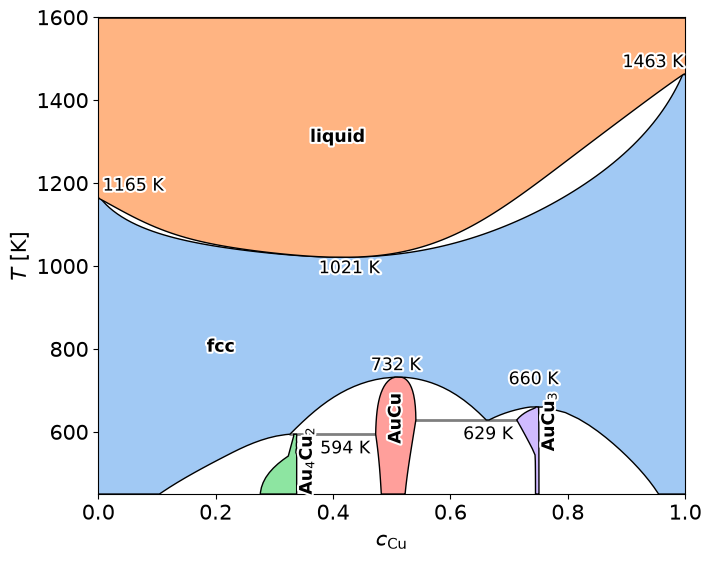

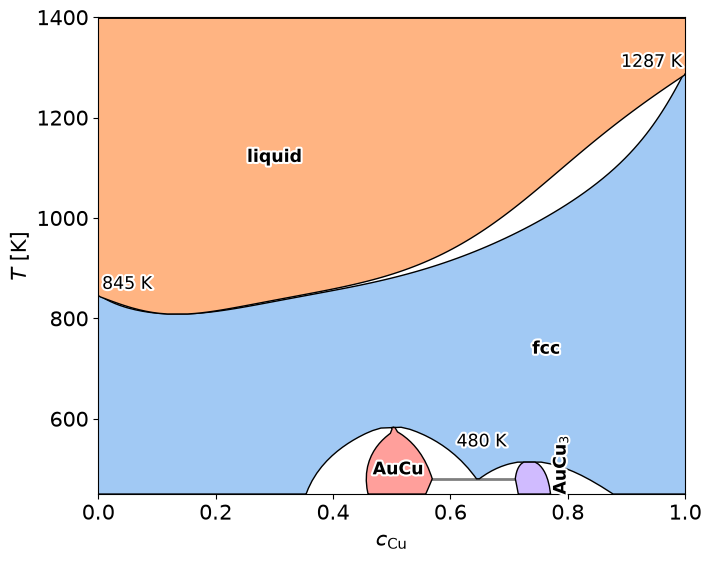

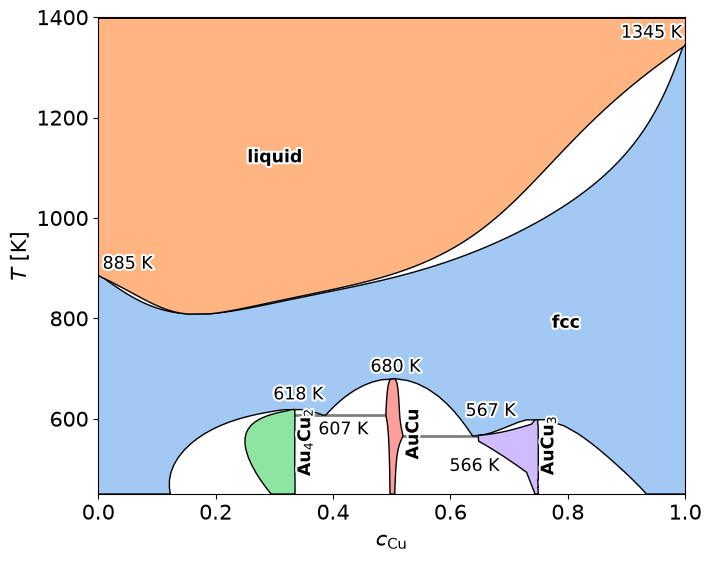

In [6]:
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})

for key, df in diagrams.items():
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    ld.plot.plot_phase_diagram(
        df, element="Cu", color_override=PHASE_COLOR, triplepoints=True, transition_temperatures=True, ax=ax,
        poly_method=ld.poly.FastTsp(min_c_width=MIN_C_WIDTH),
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(T_MIN, models[key][1])
    out = f"AuCu_Phasediagram_{key}.svg"
    fig.savefig(out)
    fig.savefig(out.replace(".svg", ".png"), dpi=DPI, transparent=True)